# Schur Complement Preconditioners for a Mixed Darcy System

## 1. Understanding the Schur Complement

In my previous notebooks, I solved the mixed Darcy system using a direct solver, MINRES, and GMRES.

Now I want to understand the Schur complement and how it can be used to build preconditioners.

The mixed Darcy system is:

$$
\begin{bmatrix}
A & -D^T \\
-D & 0
\end{bmatrix}
\begin{bmatrix}
q\\
p
\end{bmatrix}
=
\begin{bmatrix}
0\\
-F
\end{bmatrix}
$$

From the first equation:

$$
q=A^{-1}D^Tp
$$

After substituting this into the second equation:

$$
DA^{-1}D^Tp=F
$$

I define the positive Schur complement as:

$$
S=DA^{-1}D^T
$$

The pressure equation becomes:

$$
Sp=F
$$

In this step, I will use a small matrix example to understand this concept before applying it to my mixed Darcy problem.


In [1]:
# Step 1: Understanding the Schur complement

import numpy as np

# Define small example matrices
A = np.array([
    [2.0, 0.0],
    [0.0, 4.0]
])

D = np.array([
    [1.0, 1.0]
])

F = np.array([1.0])

# Calculate A inverse times D transpose
X = np.linalg.solve(A, D.T)

# Calculate the positive Schur complement
S = D @ X

# Solve the pressure equation
p = np.linalg.solve(S, F)

# Calculate the flux
q = X @ p

# Print results
print("Matrix A:")
print(A)

print("Matrix D:")
print(D)

print("Schur complement:")
print(S)

print("Pressure:", p)
print("Flux:", q)

# Check the two original equations
print("First equation satisfied:",
      np.allclose(A @ q - D.T @ p, 0))

print("Second equation satisfied:",
      np.allclose(D @ q, F))

Matrix A:
[[2. 0.]
 [0. 4.]]
Matrix D:
[[1. 1.]]
Schur complement:
[[0.75]]
Pressure: [1.33333333]
Flux: [0.66666667 0.33333333]
First equation satisfied: True
Second equation satisfied: True


### Result

I used a small matrix example to understand the Schur complement.

The positive Schur complement was 0.75.

I first calculated the pressure, which was approximately 1.33333. Then I used the pressure to calculate the flux values, which were approximately 0.66667 and 0.33333.

I also checked both original equations, and both checks returned True.

This example helped me understand how I can solve the pressure equation first and then calculate the flux using the Schur complement.

## 2. Preparing the Mixed Darcy System

In this step, I will prepare the same mixed Darcy system from my previous notebooks.

I will use a triangular mesh with RT0 elements for flux and P0 elements for pressure.

The saddle-point matrix is:

$$
G=
\begin{bmatrix}
A & -D^T \\
-D & 0
\end{bmatrix}
$$

The right-hand side is:

$$
b=
\begin{bmatrix}
0\\
-F
\end{bmatrix}
$$

I will assemble the matrices A and D, the full matrix G, and the right-hand side.

I need these matrices to calculate the Schur complement and build preconditioners in the next steps.


In [2]:
# Step 2: Prepare the mixed Darcy system

%pip -q install scikit-fem

from skfem import MeshTri, Basis, ElementTriRT0, ElementTriP0
from skfem import BilinearForm, LinearForm, asm
from skfem.helpers import dot, div
from scipy.sparse import bmat

# Create the triangular mesh
mesh = MeshTri.init_tensor(
    np.linspace(0, 1, 5),
    np.linspace(0, 1, 5)
)

# Define flux and pressure spaces
flux_basis = Basis(mesh, ElementTriRT0(), intorder=2)
pressure_basis = Basis(mesh, ElementTriP0(), intorder=2)

# Flux mass matrix
@BilinearForm
def flux_form(q, v, w):
    return dot(q, v)

# Divergence matrix
@BilinearForm
def divergence_form(q, r, w):
    return div(q) * r

# Source term
@LinearForm
def source_form(r, w):
    x = w.x[0]
    y = w.x[1]
    f = 2 * np.pi**2 * np.sin(np.pi*x) * np.sin(np.pi*y)
    return f * r

# Assemble the matrices
A = asm(flux_form, flux_basis)
D = asm(divergence_form, flux_basis, pressure_basis)

# Assemble the saddle-point matrix
G = bmat([
    [A, -D.T],
    [-D, None]
], format="csr")

# Assemble the right-hand side
F = asm(source_form, pressure_basis)
b = np.concatenate((np.zeros(flux_basis.N), -F))

# Print results
print("Number of triangles:", mesh.t.shape[1])
print("Flux degrees of freedom:", flux_basis.N)
print("Pressure degrees of freedom:", pressure_basis.N)

print("Matrix A shape:", A.shape)
print("Matrix D shape:", D.shape)
print("Matrix G shape:", G.shape)
print("Right-hand side shape:", b.shape)

print("Matrix A is symmetric:",
      np.allclose(A.toarray(), A.toarray().T))

print("Matrix G is symmetric:",
      np.allclose(G.toarray(), G.toarray().T))

Note: you may need to restart the kernel to use updated packages.
Number of triangles: 32
Flux degrees of freedom: 56
Pressure degrees of freedom: 32
Matrix A shape: (56, 56)
Matrix D shape: (32, 56)
Matrix G shape: (88, 88)
Right-hand side shape: (88,)
Matrix A is symmetric: True
Matrix G is symmetric: True


### Result

I prepared the same mixed Darcy system from my previous notebooks.

The mesh has 32 triangles, 56 flux degrees of freedom, and 32 pressure degrees of freedom.

The flux mass matrix A has a size of 56 × 56, and the divergence matrix D has a size of 32 × 56.

The full saddle-point matrix G has a size of 88 × 88.

I also checked that matrices A and G are symmetric.

Now I have the matrices that I need to calculate the Schur complement in the next step.

## 3. Calculating the Exact Schur Complement

In this step, I will calculate the exact Schur complement using the matrices A and D from my mixed Darcy system.

The positive Schur complement is:

$$
S=DA^{-1}D^T
$$

Instead of calculating the inverse of A directly, I will solve:

$$
AX=D^T
$$

Then I will calculate:

$$
S=DX
$$

I will check the size, symmetry, and eigenvalues of the Schur complement.

I also want to check whether it is positive definite.

I will use this matrix later to build a block preconditioner.


In [3]:
# Step 3: Calculate the exact Schur complement

# Convert sparse matrices to dense matrices
A_dense = A.toarray()
D_dense = D.toarray()

# Solve A X = D transpose
X = np.linalg.solve(A_dense, D_dense.T)

# Calculate the Schur complement
S = D_dense @ X

# Check symmetry
is_symmetric = np.allclose(S, S.T)

# Calculate eigenvalues
eigenvalues = np.linalg.eigvalsh(S)

# Check positive definiteness
is_positive_definite = np.all(eigenvalues > 0)

# Print results
print("Matrix A shape:", A_dense.shape)
print("Matrix D shape:", D_dense.shape)
print("Matrix X shape:", X.shape)
print("Schur complement shape:", S.shape)

print("Schur complement is symmetric:", is_symmetric)
print("Minimum eigenvalue:", np.min(eigenvalues))
print("Maximum eigenvalue:", np.max(eigenvalues))
print("Schur complement is positive definite:",
      is_positive_definite)

print("A X = D transpose satisfied:",
      np.allclose(A_dense @ X, D_dense.T))

Matrix A shape: (56, 56)
Matrix D shape: (32, 56)
Matrix X shape: (56, 32)
Schur complement shape: (32, 32)
Schur complement is symmetric: True
Minimum eigenvalue: 0.6268286683509533
Maximum eigenvalue: 17.999999999999996
Schur complement is positive definite: True
A X = D transpose satisfied: True


### Result

I calculated the exact Schur complement using the matrices A and D from my mixed Darcy system.

The Schur complement has a size of 32 × 32.

The minimum eigenvalue was approximately 0.626829, and the maximum eigenvalue was approximately 18.

I checked that the matrix is symmetric and all its eigenvalues are positive.

This means that the calculated Schur complement is symmetric positive definite.

I also checked that the equation AX = Dᵀ was satisfied.

I will use this Schur complement to build a block preconditioner in the next steps.

## 4. Building the Block Diagonal Preconditioner

In this step, I will build a block diagonal preconditioner using the flux mass matrix A and the Schur complement S.

The preconditioner is:

$$
P=
\begin{bmatrix}
A & 0 \\
0 & S
\end{bmatrix}
$$

I will check the size, symmetry, and positive definiteness of this matrix.

To use this preconditioner with an iterative solver, I need to apply its inverse:

$$
P^{-1}=
\begin{bmatrix}
A^{-1} & 0 \\
0 & S^{-1}
\end{bmatrix}
$$

Instead of calculating the inverse directly, I will solve two smaller linear systems.

I will also test the inverse action before using the preconditioner with MINRES.


In [4]:
# Step 4: Build the block diagonal preconditioner

from scipy.linalg import block_diag, cho_factor, cho_solve
from scipy.sparse.linalg import LinearOperator

# Build the block diagonal matrix
P = block_diag(A_dense, S)

# Check symmetry and positive definiteness
p_symmetric = np.allclose(P, P.T)
p_eigenvalues = np.linalg.eigvalsh(P)
p_positive = np.all(p_eigenvalues > 0)

# Number of flux unknowns
n_flux = flux_basis.N

# Factorize A and S
A_factor = cho_factor(A_dense)
S_factor = cho_factor(S)

# Apply the inverse of the preconditioner
def apply_preconditioner(r):

    # Separate flux and pressure parts
    r_flux = r[:n_flux]
    r_pressure = r[n_flux:]

    # Solve the two blocks
    y_flux = cho_solve(A_factor, r_flux)
    y_pressure = cho_solve(S_factor, r_pressure)

    # Combine the results
    return np.concatenate((y_flux, y_pressure))

# Create the inverse preconditioner operator
M = LinearOperator(
    G.shape,
    matvec=apply_preconditioner,
    dtype=float
)

# Test the inverse action
test_vector = np.ones(G.shape[0])
y_test = M @ test_vector

inverse_check = np.allclose(P @ y_test, test_vector)

# Print results
print("Preconditioner shape:", P.shape)
print("Preconditioner is symmetric:", p_symmetric)
print("Minimum eigenvalue:", np.min(p_eigenvalues))
print("Preconditioner is positive definite:", p_positive)
print("Inverse operator shape:", M.shape)
print("Inverse action check:", inverse_check)

Preconditioner shape: (88, 88)
Preconditioner is symmetric: True
Minimum eigenvalue: 0.16666666666666657
Preconditioner is positive definite: True
Inverse operator shape: (88, 88)
Inverse action check: True


### Result

I built a block diagonal preconditioner using the flux mass matrix A and the exact Schur complement S.

The preconditioner has a size of 88 × 88.

The minimum eigenvalue was approximately 0.166667.

I checked that the preconditioner is symmetric and all its eigenvalues are positive.

I also tested the inverse action using a test vector, and the check returned True.

In the next step, I will use this preconditioner with MINRES and check whether it reduces the number of iterations.

## 5. Solving the Mixed Darcy System Using Preconditioned MINRES

In this step, I will use the block diagonal preconditioner that I built in the previous step.

The preconditioner is:

$$
P=
\begin{bmatrix}
A & 0 \\
0 & S
\end{bmatrix}
$$

I will solve the mixed Darcy system using MINRES with and without the preconditioner.

I will use the same matrix and right-hand side for both tests.

I will compare the number of iterations, solver status, and actual relative residuals.

I want to check whether the preconditioner helps reduce the number of iterations.


In [5]:
# Step 5: MINRES with and without a preconditioner

from scipy.sparse.linalg import minres

# Count iterations without preconditioner
iterations_without = []

def count_without(x):
    iterations_without.append(1)

# MINRES without preconditioner
z_without, info_without = minres(
    G, b,
    rtol=1e-8,
    maxiter=500,
    callback=count_without
)

# Count iterations with preconditioner
iterations_with = []

def count_with(x):
    iterations_with.append(1)

# MINRES with preconditioner
z_with, info_with = minres(
    G, b,
    M=M,
    rtol=1e-8,
    maxiter=500,
    callback=count_with
)

# Calculate actual relative residuals
b_norm = np.linalg.norm(b)

residual_without = np.linalg.norm(
    b - G @ z_without
) / b_norm

residual_with = np.linalg.norm(
    b - G @ z_with
) / b_norm

# Print results without preconditioner
print("MINRES WITHOUT PRECONDITIONER")
print("Iterations:", len(iterations_without))
print("Solver info:", info_without)
print("Relative residual:", residual_without)
print("Meets target:", residual_without <= 1e-8)

print("--------------------------------")

# Print results with preconditioner
print("MINRES WITH PRECONDITIONER")
print("Iterations:", len(iterations_with))
print("Solver info:", info_with)
print("Relative residual:", residual_with)
print("Meets target:", residual_with <= 1e-8)

MINRES WITHOUT PRECONDITIONER
Iterations: 24
Solver info: 0
Relative residual: 4.182249841474048e-14
Meets target: True
--------------------------------
MINRES WITH PRECONDITIONER
Iterations: 2
Solver info: 0
Relative residual: 2.730962551223992e-15
Meets target: True


### Result

I solved the mixed Darcy system using MINRES with and without the block diagonal preconditioner.

Without the preconditioner, MINRES took 24 iterations. With the preconditioner, it took only 2 iterations.

The relative residual without the preconditioner was approximately 4.18 × 10⁻¹⁴, while with the preconditioner it was approximately 2.73 × 10⁻¹⁵.

Both solvers reached my target relative residual of 10⁻⁸.

The number of iterations decreased by approximately 91.67% after using the preconditioner.

This result shows that the block diagonal preconditioner reduced the number of iterations for my current problem.

I still need to check the computation time and test larger meshes.

## 6. Solving the Mixed Darcy System Using Preconditioned GMRES

In the previous step, I tested MINRES with a block diagonal preconditioner.

Now I want to test GMRES using the same preconditioner.

The preconditioner is:

$$
P=
\begin{bmatrix}
A & 0 \\
0 & S
\end{bmatrix}
$$

I will solve the mixed Darcy system using GMRES with and without the preconditioner.

I will compare the iteration counts, solver status, and actual relative residuals.

I want to see whether the preconditioner also reduces the number of iterations for GMRES.


In [6]:
# Step 6: GMRES with and without a preconditioner

from scipy.sparse.linalg import gmres

# Count iterations without preconditioner
gmres_without_steps = []

def count_gmres_without(r):
    gmres_without_steps.append(1)

# GMRES without preconditioner
z_gmres_without, info_gmres_without = gmres(
    G, b,
    rtol=1e-8,
    atol=0.0,
    restart=50,
    maxiter=20,
    callback=count_gmres_without,
    callback_type="pr_norm"
)

# Count iterations with preconditioner
gmres_with_steps = []

def count_gmres_with(r):
    gmres_with_steps.append(1)

# GMRES with preconditioner
z_gmres_with, info_gmres_with = gmres(
    G, b,
    M=M,
    rtol=1e-8,
    atol=0.0,
    restart=50,
    maxiter=20,
    callback=count_gmres_with,
    callback_type="pr_norm"
)

# Calculate actual relative residuals
b_norm = np.linalg.norm(b)

gmres_residual_without = np.linalg.norm(
    b - G @ z_gmres_without
) / b_norm

gmres_residual_with = np.linalg.norm(
    b - G @ z_gmres_with
) / b_norm

# Print results without preconditioner
print("GMRES WITHOUT PRECONDITIONER")
print("Iterations:", len(gmres_without_steps))
print("Solver info:", info_gmres_without)
print("Relative residual:", gmres_residual_without)
print("Meets target:", gmres_residual_without <= 1e-8)

print("--------------------------------")

# Print results with preconditioner
print("GMRES WITH PRECONDITIONER")
print("Iterations:", len(gmres_with_steps))
print("Solver info:", info_gmres_with)
print("Relative residual:", gmres_residual_with)
print("Meets target:", gmres_residual_with <= 1e-8)

GMRES WITHOUT PRECONDITIONER
Iterations: 24
Solver info: 0
Relative residual: 2.5188061430785e-14
Meets target: True
--------------------------------
GMRES WITH PRECONDITIONER
Iterations: 2
Solver info: 0
Relative residual: 3.0419440974409174e-15
Meets target: True


### Result

I solved the mixed Darcy system using GMRES with and without the block diagonal preconditioner.

Without the preconditioner, GMRES took 24 iterations. With the preconditioner, it took only 2 iterations.

The relative residual without the preconditioner was approximately 2.52 × 10⁻¹⁴, while with the preconditioner it was approximately 3.04 × 10⁻¹⁵.

Both solutions reached my target relative residual of 10⁻⁸.

The number of iterations decreased by approximately 91.67%.

I also noticed that both MINRES and GMRES took only 2 iterations when I used the same block diagonal preconditioner.

I still need to compare their computation times and test larger meshes.

## 7. Building the Block Triangular Preconditioner

In this step, I will build a lower block triangular preconditioner.

The preconditioner is:

$$
P_T=
\begin{bmatrix}
A & 0\\
-D & -S
\end{bmatrix}
$$

where

$$
S=DA^{-1}D^T
$$

Unlike the block diagonal preconditioner, this preconditioner is not symmetric.

To apply its inverse, I will solve:

$$
y_q=A^{-1}r_q
$$

and

$$
y_p=-S^{-1}(r_p+Dy_q)
$$

I will use the same matrices and Cholesky factors from the previous steps.

I will check the matrix size, symmetry, and inverse action before using this preconditioner with GMRES.


In [7]:
# Step 7: Build the block triangular preconditioner

# Create the zero block
zero_block = np.zeros((A_dense.shape[0], S.shape[0]))

# Build the lower block triangular matrix
P_tri = np.block([
    [A_dense, zero_block],
    [-D_dense, -S]
])

# Check symmetry
tri_symmetric = np.allclose(P_tri, P_tri.T)

# Apply the inverse of the preconditioner
def apply_triangular(r):

    # Separate flux and pressure parts
    r_flux = r[:n_flux]
    r_pressure = r[n_flux:]

    # Solve the flux block
    y_flux = cho_solve(A_factor, r_flux)

    # Solve the pressure block
    y_pressure = -cho_solve(
        S_factor, r_pressure + D_dense @ y_flux
    )

    # Combine the results
    return np.concatenate((y_flux, y_pressure))

# Create the inverse operator
M_tri = LinearOperator(
    G.shape,
    matvec=apply_triangular,
    dtype=float
)

# Test the inverse action
test_vector = np.ones(G.shape[0])
y_tri = M_tri @ test_vector

tri_inverse_check = np.allclose(
    P_tri @ y_tri, test_vector
)

# Print results
print("Triangular preconditioner shape:", P_tri.shape)
print("Preconditioner is symmetric:", tri_symmetric)
print("Inverse operator shape:", M_tri.shape)
print("Inverse action check:", tri_inverse_check)

Triangular preconditioner shape: (88, 88)
Preconditioner is symmetric: False
Inverse operator shape: (88, 88)
Inverse action check: True


### Result

I built a lower block triangular preconditioner using the matrices A, D, and S.

The preconditioner has a size of 88 × 88.

I checked its symmetry, and the result was False. This was expected because the block triangular preconditioner is not symmetric.

I also tested the inverse action using a test vector, and the check returned True.

In the next step, I will use this preconditioner with GMRES and compare the results with the block diagonal preconditioner.

## 8. Testing GMRES with the Block Triangular Preconditioner

In this step, I will use the block triangular preconditioner with GMRES.

The preconditioner is:

$$
P_T=
\begin{bmatrix}
A & 0\\
-D & -S
\end{bmatrix}
$$

The preconditioned system is:

$$
P_T^{-1}Gz=P_T^{-1}b
$$

I will compare three cases:

- GMRES without a preconditioner.
- GMRES with a block diagonal preconditioner.
- GMRES with a block triangular preconditioner.

I will compare the iteration counts and actual relative residuals.

I want to see how the block triangular preconditioner performs for my current Darcy system.


In [11]:
# Step 8: GMRES with a block triangular preconditioner

# Count iterations
gmres_tri_steps = []

def count_gmres_tri(r):
    gmres_tri_steps.append(1)

# Run GMRES with the triangular preconditioner
z_gmres_tri, info_gmres_tri = gmres(
    G, b,
    M=M_tri,
    rtol=1e-8,
    atol=0.0,
    restart=50,
    maxiter=20,
    callback=count_gmres_tri,
    callback_type="pr_norm"
)

# Calculate the actual relative residual
gmres_residual_tri = (
    np.linalg.norm(b - G @ z_gmres_tri)
    / np.linalg.norm(b)
)

# Print results
print("GMRES WITH BLOCK TRIANGULAR PRECONDITIONER")
print("Iterations:", len(gmres_tri_steps))
print("Solver info:", info_gmres_tri)
print("Relative residual:", gmres_residual_tri)
print("Meets target:", gmres_residual_tri <= 1e-8)

print("-----------------------------------------")

# Compare all three cases
print("GMRES COMPARISON")

print("Without preconditioner:")
print("Iterations:", len(gmres_without_steps))
print("Relative residual:", gmres_residual_without)

print("With block diagonal preconditioner:")
print("Iterations:", len(gmres_with_steps))
print("Relative residual:", gmres_residual_with)

print("With block triangular preconditioner:")
print("Iterations:", len(gmres_tri_steps))
print("Relative residual:", gmres_residual_tri)

GMRES WITH BLOCK TRIANGULAR PRECONDITIONER
Iterations: 2
Solver info: 0
Relative residual: 3.093544011798897e-15
Meets target: True
-----------------------------------------
GMRES COMPARISON
Without preconditioner:
Iterations: 24
Relative residual: 2.5188061430785e-14
With block diagonal preconditioner:
Iterations: 2
Relative residual: 3.0419440974409174e-15
With block triangular preconditioner:
Iterations: 2
Relative residual: 3.093544011798897e-15


### Result

I tested GMRES using the block triangular preconditioner.

GMRES converged in 2 iterations and gave a relative residual of approximately 3.09 × 10⁻¹⁵.

Without a preconditioner, GMRES took 24 iterations.

With the block diagonal and block triangular preconditioners, GMRES took only 2 iterations in both cases.

Both preconditioners reduced the number of iterations by approximately 91.67%.

For my current problem, both preconditioners gave similar results in terms of iteration counts and relative residuals.

I still need to compare their computation times and test their performance on larger meshes.

## 9. Calculating the Approximate Schur Complement

In the previous steps, I used the exact Schur complement to build preconditioners.

Calculating the exact Schur complement can be expensive for larger systems.

In this step, I will calculate an approximate Schur complement using the diagonal elements of A.

The exact Schur complement is:

$$
S=DA^{-1}D^T
$$

The approximate Schur complement is:

$$
\widetilde{S}=D\,\operatorname{diag}(A)^{-1}D^T
$$

I will build a new block diagonal preconditioner:

$$
\widetilde{P}=
\begin{bmatrix}
A & 0\\
0 & \widetilde{S}
\end{bmatrix}
$$

I will check the symmetry and positive definiteness of the approximate Schur complement.

I will also test the inverse action of the new preconditioner before using it with MINRES and GMRES.

In [13]:
# Step 9: Calculate the approximate Schur complement

from scipy.sparse import diags

# Get the diagonal elements of A
A_diagonal = A.diagonal()

# Calculate the inverse of the diagonal matrix
A_diagonal_inverse = diags(1.0 / A_diagonal)

# Calculate the approximate Schur complement
S_approx = (D @ A_diagonal_inverse @ D.T).toarray()

# Check symmetry and positive definiteness
approx_symmetric = np.allclose(S_approx, S_approx.T)

approx_eigenvalues = np.linalg.eigvalsh(S_approx)

approx_positive = np.all(approx_eigenvalues > 0)

# Build the approximate block diagonal preconditioner
P_approx = block_diag(A_dense, S_approx)

# Factorize the approximate Schur complement
S_approx_factor = cho_factor(S_approx)

# Apply the inverse of the preconditioner
def apply_approximate(r):

    r_flux = r[:n_flux]
    r_pressure = r[n_flux:]

    y_flux = cho_solve(A_factor, r_flux)
    y_pressure = cho_solve(S_approx_factor, r_pressure)

    return np.concatenate((y_flux, y_pressure))

# Create the inverse operator
M_approx = LinearOperator(
    G.shape,
    matvec=apply_approximate,
    dtype=float
)

# Test the inverse action
test_vector = np.ones(G.shape[0])
y_approx = M_approx @ test_vector

approx_inverse_check = np.allclose(
    P_approx @ y_approx, test_vector
)

# Print results
print("Approximate Schur complement shape:", S_approx.shape)
print("Schur complement is symmetric:", approx_symmetric)
print("Minimum eigenvalue:", np.min(approx_eigenvalues))
print("Maximum eigenvalue:", np.max(approx_eigenvalues))
print("Schur complement is positive definite:", approx_positive)

print("-----------------------------------")

print("Preconditioner shape:", P_approx.shape)
print("Inverse operator shape:", M_approx.shape)
print("Inverse action check:", approx_inverse_check)

Approximate Schur complement shape: (32, 32)
Schur complement is symmetric: True
Minimum eigenvalue: 0.6590864603711739
Maximum eigenvalue: 12.0
Schur complement is positive definite: True
-----------------------------------
Preconditioner shape: (88, 88)
Inverse operator shape: (88, 88)
Inverse action check: True


### Result

I calculated the approximate Schur complement using the diagonal elements of matrix A.

The approximate Schur complement has a size of 32 × 32.

The minimum eigenvalue was approximately 0.659086, and the maximum eigenvalue was 12.

I checked that the matrix is symmetric and positive definite.

I also built a block diagonal preconditioner using the approximate Schur complement.

The inverse action check returned True.

In the next step, I will test this preconditioner with MINRES and GMRES and compare the results with the exact Schur complement preconditioner.

## 10. Testing MINRES and GMRES with the Approximate Schur Complement

In this step, I will test MINRES and GMRES using the approximate block diagonal preconditioner.

The preconditioner is:

$$
\widetilde{P}=
\begin{bmatrix}
A & 0\\
0 & \widetilde{S}
\end{bmatrix}
$$

where

$$
\widetilde{S}=D\,\operatorname{diag}(A)^{-1}D^T
$$

I will use the same Darcy system and solver settings from my previous tests.

I will compare three cases:

- Without a preconditioner.
- With the exact block diagonal preconditioner.
- With the approximate block diagonal preconditioner.

I will check the iteration counts and actual relative residuals.

I want to see how the approximate Schur complement affects solver convergence.


In [15]:
# Step 10: Test the approximate Schur complement

# Count MINRES iterations
minres_approx_steps = []

def count_minres_approx(x):
    minres_approx_steps.append(1)

# Run MINRES with approximate preconditioner
z_minres_approx, info_minres_approx = minres(
    G, b,
    M=M_approx,
    rtol=1e-8,
    maxiter=500,
    callback=count_minres_approx
)

# Count GMRES iterations
gmres_approx_steps = []

def count_gmres_approx(r):
    gmres_approx_steps.append(1)

# Run GMRES with approximate preconditioner
z_gmres_approx, info_gmres_approx = gmres(
    G, b,
    M=M_approx,
    rtol=1e-8,
    atol=0.0,
    restart=50,
    maxiter=20,
    callback=count_gmres_approx,
    callback_type="pr_norm"
)

# Calculate actual relative residuals
b_norm = np.linalg.norm(b)

minres_residual_approx = np.linalg.norm(
    b - G @ z_minres_approx
) / b_norm

gmres_residual_approx = np.linalg.norm(
    b - G @ z_gmres_approx
) / b_norm

# Print MINRES results
print("MINRES WITH APPROXIMATE PRECONDITIONER")
print("Iterations:", len(minres_approx_steps))
print("Solver info:", info_minres_approx)
print("Relative residual:", minres_residual_approx)
print("Meets target:", minres_residual_approx <= 1e-8)

print("----------------------------------------")

# Print GMRES results
print("GMRES WITH APPROXIMATE PRECONDITIONER")
print("Iterations:", len(gmres_approx_steps))
print("Solver info:", info_gmres_approx)
print("Relative residual:", gmres_residual_approx)
print("Meets target:", gmres_residual_approx <= 1e-8)

print("----------------------------------------")

# Compare iteration counts
print("MINRES COMPARISON")
print("Without preconditioner:", len(iterations_without))
print("Exact preconditioner:", len(iterations_with))
print("Approximate preconditioner:", len(minres_approx_steps))

print("----------------------------------------")

print("GMRES COMPARISON")
print("Without preconditioner:", len(gmres_without_steps))
print("Exact preconditioner:", len(gmres_with_steps))
print("Approximate preconditioner:", len(gmres_approx_steps))

MINRES WITH APPROXIMATE PRECONDITIONER
Iterations: 16
Solver info: 0
Relative residual: 6.053826396623089e-08
Meets target: False
----------------------------------------
GMRES WITH APPROXIMATE PRECONDITIONER
Iterations: 20
Solver info: 0
Relative residual: 2.4964691546181596e-09
Meets target: True
----------------------------------------
MINRES COMPARISON
Without preconditioner: 24
Exact preconditioner: 2
Approximate preconditioner: 16
----------------------------------------
GMRES COMPARISON
Without preconditioner: 24
Exact preconditioner: 2
Approximate preconditioner: 20


### Result

I tested MINRES and GMRES using the approximate Schur complement preconditioner.

MINRES took 16 iterations, while GMRES took 20 iterations.

The relative residual was approximately 6.05 × 10⁻⁸ for MINRES and 2.50 × 10⁻⁹ for GMRES.

Both solvers returned `info = 0`, but only GMRES reached my actual relative residual target of 10⁻⁸.

The approximate preconditioner reduced the number of iterations for both solvers compared with the runs without preconditioners.

However, both solvers needed more iterations than they did with the exact Schur complement.

I will test MINRES with a stricter tolerance before comparing the results further.

I also need to check the computational cost of both preconditioners.

## 11. Testing Approximate Preconditioned MINRES with a Stricter Tolerance

In the previous step, MINRES did not reach my actual relative residual target when I used the approximate preconditioner.

I want to check whether using a smaller tolerance helps reduce the residual.

I will test three different tolerances:

- 10⁻⁸
- 10⁻¹⁰
- 10⁻¹²

I will use the same Darcy system and approximate preconditioner for all three tests.

I will record the iteration counts, solver status, and actual relative residuals.

My target relative residual is still 10⁻⁸.


In [16]:
# Step 11: Test MINRES with stricter tolerances

# Define tolerances and residual target
tolerances = [1e-8, 1e-10, 1e-12]
target = 1e-8

# Test each tolerance
for tol in tolerances:

    # Count iterations
    approx_test_steps = []

    def count_approx_test(x):
        approx_test_steps.append(1)

    # Run preconditioned MINRES
    z_approx_test, info_approx_test = minres(
        G, b,
        M=M_approx,
        rtol=tol,
        maxiter=500,
        callback=count_approx_test
    )

    # Calculate the actual relative residual
    actual_residual = (
        np.linalg.norm(b - G @ z_approx_test)
        / np.linalg.norm(b)
    )

    # Print results
    print("Requested tolerance:", tol)
    print("Iterations:", len(approx_test_steps))
    print("Solver info:", info_approx_test)
    print("Actual relative residual:", actual_residual)
    print("Meets target:", actual_residual <= target)

    print("------------------------------------")

Requested tolerance: 1e-08
Iterations: 16
Solver info: 0
Actual relative residual: 6.053826396623089e-08
Meets target: False
------------------------------------
Requested tolerance: 1e-10
Iterations: 20
Solver info: 0
Actual relative residual: 7.406036060805277e-16
Meets target: True
------------------------------------
Requested tolerance: 1e-12
Iterations: 20
Solver info: 0
Actual relative residual: 7.406036060805277e-16
Meets target: True
------------------------------------


### Result

I tested MINRES with the approximate Schur complement preconditioner using three different tolerances.

With a tolerance of 10⁻⁸, MINRES took 16 iterations but did not reach my actual relative residual target.

When I changed the tolerance to 10⁻¹⁰, MINRES took 20 iterations and gave a relative residual of approximately 7.41 × 10⁻¹⁶.

I got the same result with a tolerance of 10⁻¹².

This shows that a requested tolerance of 10⁻¹⁰ is sufficient for my current problem.

Both MINRES and GMRES took 20 iterations with the approximate preconditioner while meeting my residual target.

The number of iterations decreased from 24 to 20, which is a reduction of approximately 16.67%.

I still need to test these preconditioners on larger meshes and compare their computation times.

## 12. Testing Schur Complement Preconditioners on Different Mesh Sizes

In this step, I will test the preconditioners on different mesh sizes.

I will use three mesh sizes:

- 4 × 4
- 8 × 8
- 16 × 16

For each mesh, I will assemble the mixed Darcy system and build the preconditioners again.

I will test MINRES and GMRES without a preconditioner, with the exact block diagonal preconditioner, and with the approximate block diagonal preconditioner.

I will also test GMRES with the exact block triangular preconditioner.

I will compare the iteration counts and actual relative residuals.

If MINRES does not reach my residual target, I will test it with a stricter tolerance.

My target relative residual is still 10⁻⁸.

I want to understand how the preconditioners perform when the mesh size increases.

In [21]:
# Step 12: Test preconditioners on different mesh sizes

import pandas as pd

# Function to assemble the mixed Darcy system
def build_test_system(n):

    mesh_test = MeshTri.init_tensor(
        np.linspace(0, 1, n + 1),
        np.linspace(0, 1, n + 1)
    )

    flux_test = Basis(
        mesh_test, ElementTriRT0(), intorder=2
    )

    pressure_test = Basis(
        mesh_test, ElementTriP0(), intorder=2
    )

    A_test = asm(flux_form, flux_test)

    D_test = asm(
        divergence_form, flux_test, pressure_test
    )

    F_test = asm(source_form, pressure_test)

    G_test = bmat([
        [A_test, -D_test.T],
        [-D_test, None]
    ], format="csr")

    b_test = np.concatenate((
        np.zeros(flux_test.N), -F_test
    ))

    return A_test, D_test, G_test, b_test


# Function to build a preconditioner
def build_test_preconditioner(A_test, D_test, G_test, kind):

    A_local = A_test.toarray()
    D_local = D_test.toarray()

    n_flux_local = A_test.shape[0]

    A_local_factor = cho_factor(A_local)

    # Calculate the Schur complement
    if kind == "Approximate diagonal":

        A_diag_inv = diags(1.0 / A_test.diagonal())

        S_local = (
            D_test @ A_diag_inv @ D_test.T
        ).toarray()

    else:

        X_local = cho_solve(
            A_local_factor, D_local.T
        )

        S_local = D_local @ X_local

    S_local_factor = cho_factor(S_local)

    # Apply the inverse preconditioner
    def apply_local(r):

        r_flux = r[:n_flux_local]
        r_pressure = r[n_flux_local:]

        y_flux = cho_solve(A_local_factor, r_flux)

        if kind == "Exact triangular":

            y_pressure = -cho_solve(
                S_local_factor,
                r_pressure + D_local @ y_flux
            )

        else:

            y_pressure = cho_solve(
                S_local_factor, r_pressure
            )

        return np.concatenate((y_flux, y_pressure))

    return LinearOperator(
        G_test.shape,
        matvec=apply_local,
        dtype=float
    )


# Function to run the iterative solver
def run_mesh_solver(G_test, b_test, solver, M_test, tol):

    steps = []

    def count_steps(value):
        steps.append(1)

    if solver == "MINRES":

        z_test, info_test = minres(
            G_test, b_test,
            M=M_test,
            rtol=tol,
            maxiter=3000,
            callback=count_steps
        )

    else:

        z_test, info_test = gmres(
            G_test, b_test,
            M=M_test,
            rtol=tol,
            atol=0.0,
            restart=50,
            maxiter=60,
            callback=count_steps,
            callback_type="pr_norm"
        )

    residual_test = (
        np.linalg.norm(b_test - G_test @ z_test)
        / np.linalg.norm(b_test)
    )

    return len(steps), info_test, residual_test


# Define mesh sizes and residual target
mesh_sizes = [4, 8, 16]
mesh_target = 1e-8

mesh_results = []

# Define solver and preconditioner combinations
mesh_cases = [
    ("MINRES", "Without"),
    ("MINRES", "Exact diagonal"),
    ("MINRES", "Approximate diagonal"),
    ("GMRES", "Without"),
    ("GMRES", "Exact diagonal"),
    ("GMRES", "Exact triangular"),
    ("GMRES", "Approximate diagonal")
]

# Test each mesh
for n in mesh_sizes:

    A_test, D_test, G_test, b_test = build_test_system(n)

    # Build preconditioners for the current mesh
    preconditioners = {
        "Without": None
    }

    for kind in [
        "Exact diagonal",
        "Exact triangular",
        "Approximate diagonal"
    ]:

        preconditioners[kind] = build_test_preconditioner(
            A_test, D_test, G_test, kind
        )

    # Run each solver and preconditioner combination
    for solver, kind in mesh_cases:

        M_test = preconditioners[kind]

        if solver == "MINRES":
            test_tolerances = [1e-8, 1e-10, 1e-12, 1e-14]
        else:
            test_tolerances = [1e-8]

        # Use a stricter tolerance if needed
        for tol in test_tolerances:

            count, info_test, residual_test = run_mesh_solver(
                G_test, b_test, solver, M_test, tol
            )

            if info_test == 0 and residual_test <= mesh_target:
                break

        # Store results
        mesh_results.append({
            "Mesh": f"{n} x {n}",
            "DOFs": G_test.shape[0],
            "Solver": solver,
            "Preconditioner": kind,
            "Tolerance": tol,
            "Iterations": count,
            "Info": info_test,
            "Relative residual": residual_test,
            "Meets target": residual_test <= mesh_target
        })

# Create and print the results table
mesh_results_df = pd.DataFrame(mesh_results)

from IPython.display import display

display(
    mesh_results_df.style.format({"Tolerance": "{:.0e}",
    "Relative residual": "{:.6e}"})
    .hide(axis="index")
)

Mesh,DOFs,Solver,Preconditioner,Tolerance,Iterations,Info,Relative residual,Meets target
4 x 4,88,MINRES,Without,1e-08,24,0,4.182250e-14,True
4 x 4,88,MINRES,Exact diagonal,1e-08,2,0,2.419212e-15,True
4 x 4,88,MINRES,Approximate diagonal,1e-10,20,0,7.406036e-16,True
4 x 4,88,GMRES,Without,1e-08,24,0,2.518806e-14,True
4 x 4,88,GMRES,Exact diagonal,1e-08,2,0,2.486363e-15,True
4 x 4,88,GMRES,Exact triangular,1e-08,2,0,2.654363e-15,True
4 x 4,88,GMRES,Approximate diagonal,1e-08,20,0,2.496469e-09,True
8 x 8,336,MINRES,Without,1e-12,88,0,6.122140e-11,True
8 x 8,336,MINRES,Exact diagonal,1e-08,2,0,8.965740e-15,True
8 x 8,336,MINRES,Approximate diagonal,1e-10,26,0,6.645189e-09,True


### Result

I tested the Schur complement preconditioners on three different mesh sizes.

The total number of degrees of freedom increased from 88 to 336 and then to 1312.

All 21 tests reached my actual relative residual target of 10⁻⁸.

Without a preconditioner, the number of iterations increased as the mesh became finer.

With the exact Schur complement preconditioners, the number of iterations remained constant at 2 for all three mesh sizes.

With the approximate block diagonal preconditioner, the number of iterations increased slowly compared with the cases without a preconditioner.

For the largest mesh, the approximate preconditioner reduced the MINRES iterations from 173 to 34 and the GMRES iterations from 363 to 32.

This corresponds to an iteration reduction of approximately 80.35% for MINRES and 91.18% for GMRES.

These results helped me understand the effect of Schur complement preconditioners on solver convergence for different mesh sizes.

I still need to compare the computation times and the cost of building the preconditioners.

## 13. Plotting the Iteration Counts for Different Mesh Sizes

In this step, I will visualize the numerical results from the previous step.

I will plot the iteration counts for MINRES and GMRES using different preconditioners.

The x-axis represents the mesh size, and the y-axis represents the number of iterations.

I will use these graphs to understand how the iteration counts change when the mesh becomes finer.

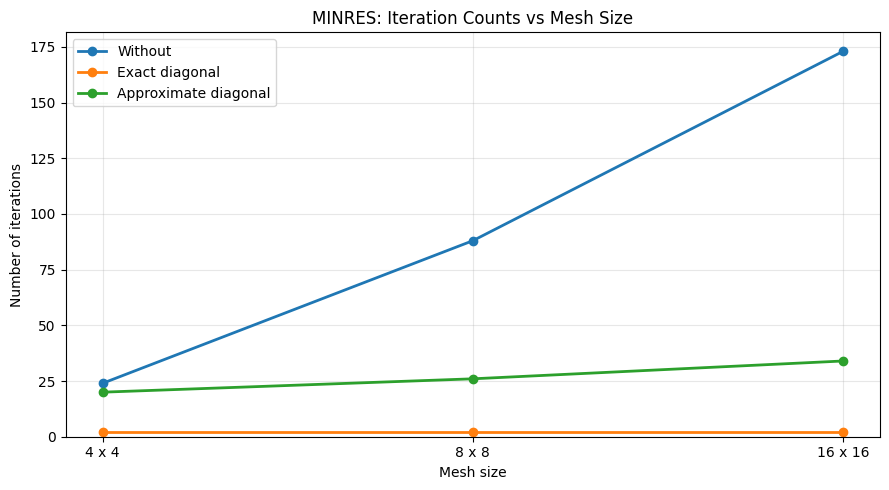

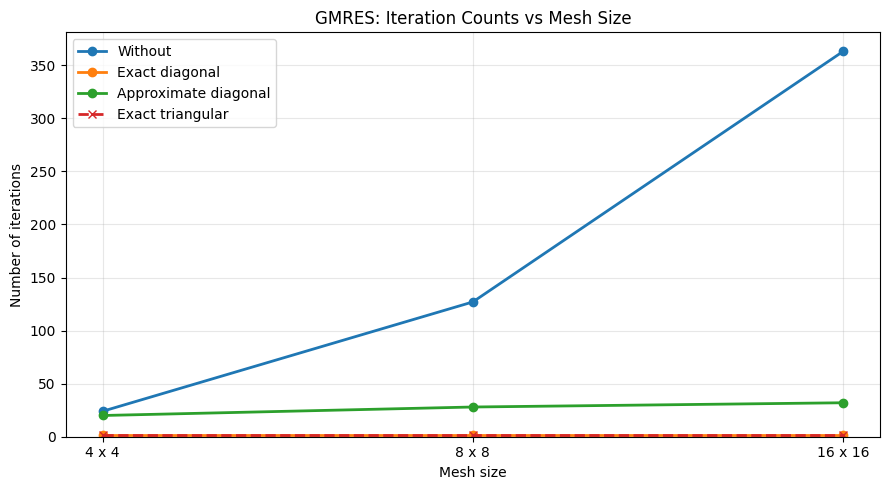

In [23]:
# Step 13: Plot iteration counts

import matplotlib.pyplot as plt

# Plot MINRES results
plt.figure(figsize=(9, 5))

minres_data = mesh_results_df[
    mesh_results_df["Solver"] == "MINRES"
]

for kind in ["Without", "Exact diagonal", "Approximate diagonal"]:

    data = minres_data[
        minres_data["Preconditioner"] == kind
    ]

    plt.plot(
        data["Mesh"],
        data["Iterations"],
        marker="o",
        linewidth=2,
        label=kind
    )

plt.xlabel("Mesh size")
plt.ylabel("Number of iterations")
plt.title("MINRES: Iteration Counts vs Mesh Size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()


# Plot GMRES results
plt.figure(figsize=(9, 5))

gmres_data = mesh_results_df[
    mesh_results_df["Solver"] == "GMRES"
]

for kind in [
    "Without",
    "Exact diagonal",
    "Approximate diagonal",
    "Exact triangular"
]:

    data = gmres_data[
        gmres_data["Preconditioner"] == kind
    ]

    plt.plot(
        data["Mesh"],
        data["Iterations"],
        marker="x" if kind == "Exact triangular" else "o",
        linestyle="--" if kind == "Exact triangular" else "-",
        linewidth=2,
        label=kind
    )

plt.xlabel("Mesh size")
plt.ylabel("Number of iterations")
plt.title("GMRES: Iteration Counts vs Mesh Size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

### Result

I plotted the iteration counts for MINRES and GMRES using different mesh sizes and preconditioners.

Both graphs show that the number of iterations increases rapidly without a preconditioner.

With the exact Schur complement preconditioners, the number of iterations remains constant at 2 for all three tested mesh sizes.

With the approximate preconditioner, the number of iterations increases slowly.

In the GMRES graph, the lines for the exact block diagonal and exact block triangular preconditioners overlap because they have the same iteration counts.

These graphs helped me visualize the effect of preconditioning on solver convergence.

I still need to compare the computational costs of these methods.

## 14. Comparing Computation Time and Preconditioner Setup Cost

In the previous steps, I compared the iteration counts and relative residuals of different preconditioners.

A smaller number of iterations does not always mean a smaller computation time because building a preconditioner also requires computational effort.

In this step, I will calculate:

- Preconditioner setup time.
- Solver execution time, including the residual check.
- Total computation time.

The total computation time is:

$$
T_{\text{total}}=T_{\text{setup}}+T_{\text{solve}}
$$

I will repeat each test five times and calculate the average time.

I will use the same mesh sizes and solver tolerances from Step 12.

I will exclude the matrix assembly time from this comparison.

My objective is to understand the computational cost of the different preconditioning methods.

In [24]:
# Step 14: Compare computation time

from time import perf_counter

# Number of repeated tests
repetitions = 5

# Store timing results
time_results = []

# Test each mesh size
for n in mesh_sizes:

    # Assemble the system outside the timing measurement
    A_time, D_time, G_time, b_time = build_test_system(n)

    # Get verified results from Step 12
    current_results = mesh_results_df[
        mesh_results_df["Mesh"] == f"{n} x {n}"
    ]

    # Test each solver and preconditioner
    for _, row in current_results.iterrows():

        solver = row["Solver"]
        kind = row["Preconditioner"]
        tol = row["Tolerance"]

        setup_times = []
        solve_times = []
        total_times = []
        target_checks = []

        # Repeat each test five times
        for repeat in range(repetitions):

            # Measure preconditioner setup time
            if kind == "Without":

                M_time = None
                setup_time = 0.0

            else:

                start_setup = perf_counter()

                M_time = build_test_preconditioner(
                    A_time, D_time, G_time, kind
                )

                setup_time = perf_counter() - start_setup

            # Measure solver execution time
            start_solve = perf_counter()

            count, info_time, residual_time = run_mesh_solver(
                G_time, b_time, solver, M_time, tol
            )

            solve_time = perf_counter() - start_solve

            # Store times in milliseconds
            setup_times.append(setup_time * 1000)
            solve_times.append(solve_time * 1000)

            total_times.append(
                (setup_time + solve_time) * 1000
            )

            # Check the residual target
            target_checks.append(
                info_time == 0 and residual_time <= 1e-8
            )

        # Store average timing results
        time_results.append({
            "Mesh": f"{n} x {n}",
            "DOFs": G_time.shape[0],
            "Solver": solver,
            "Preconditioner": kind,
            "Setup time (ms)": np.mean(setup_times),
            "Solve time (ms)": np.mean(solve_times),
            "Total time (ms)": np.mean(total_times),
            "All runs passed": all(target_checks)
        })

# Create the results table
time_results_df = pd.DataFrame(time_results)

# Display a formatted table
display(
    time_results_df.style
    .format({
        "Setup time (ms)": "{:.4f}",
        "Solve time (ms)": "{:.4f}",
        "Total time (ms)": "{:.4f}"
    })
    .hide(axis="index")
)

Mesh,DOFs,Solver,Preconditioner,Setup time (ms),Solve time (ms),Total time (ms),All runs passed
4 x 4,88,MINRES,Without,0.0000,1.4044,1.4044,True
4 x 4,88,MINRES,Exact diagonal,0.9601,0.5605,1.5206,True
4 x 4,88,MINRES,Approximate diagonal,1.1478,3.5875,4.7353,True
4 x 4,88,GMRES,Without,0.0000,7.9459,7.9459,True
4 x 4,88,GMRES,Exact diagonal,0.2772,0.8074,1.0846,True
4 x 4,88,GMRES,Exact triangular,0.2693,0.7420,1.0113,True
4 x 4,88,GMRES,Approximate diagonal,1.1187,6.6604,7.7792,True
8 x 8,336,MINRES,Without,0.0000,7.9023,7.9023,True
8 x 8,336,MINRES,Exact diagonal,24.1516,1.2623,25.4139,True
8 x 8,336,MINRES,Approximate diagonal,6.6577,16.8098,23.4676,True


### Result

I compared the computation times of MINRES and GMRES using different Schur complement preconditioners.

I repeated each configuration five times, and all 105 runs reached my residual target.

I observed that reducing the number of iterations does not always reduce the total computation time.

For MINRES, the runs without a preconditioner had the lowest total computation time for all three tested mesh sizes.

For the largest mesh, MINRES with the exact block diagonal preconditioner needed only 2 iterations, but its total computation time was approximately 152.72 ms.

The total computation time without a preconditioner was approximately 19.56 ms.

For GMRES, the approximate block diagonal preconditioner gave the lowest total computation time for the largest mesh.

Its total computation time was approximately 123.13 ms, compared with 150.79 ms without a preconditioner.

I also observed that the approximate Schur complement had a lower setup cost than the exact Schur complement for the two larger meshes.

This experiment helped me understand the importance of considering both iteration counts and computational costs when studying preconditioners.

These results are based on my current implementation using dense Cholesky factorization. I did not include the matrix assembly time.

These computation times may change when I run the notebook again.

## 15. Plotting Computation Time and Preconditioner Setup Cost

In this step, I will visualize the computation times from the previous step.

I will plot the total computation time against different mesh sizes for MINRES and GMRES.

I will also use stacked bar charts to compare the preconditioner setup time and solver execution time for the largest mesh.

The total computation time is:

$$
T_{\text{total}}=T_{\text{setup}}+T_{\text{solve}}
$$

These graphs will help me understand the computational cost of different preconditioners and the relationship between iteration counts and computation time.

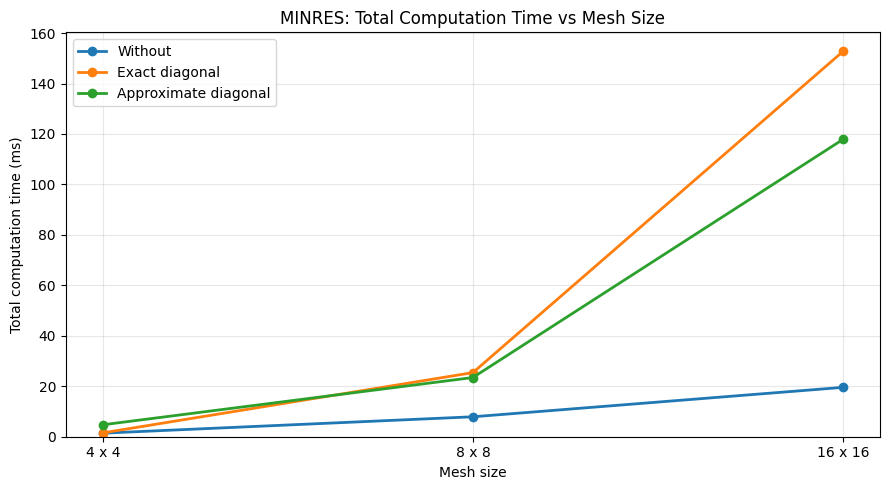

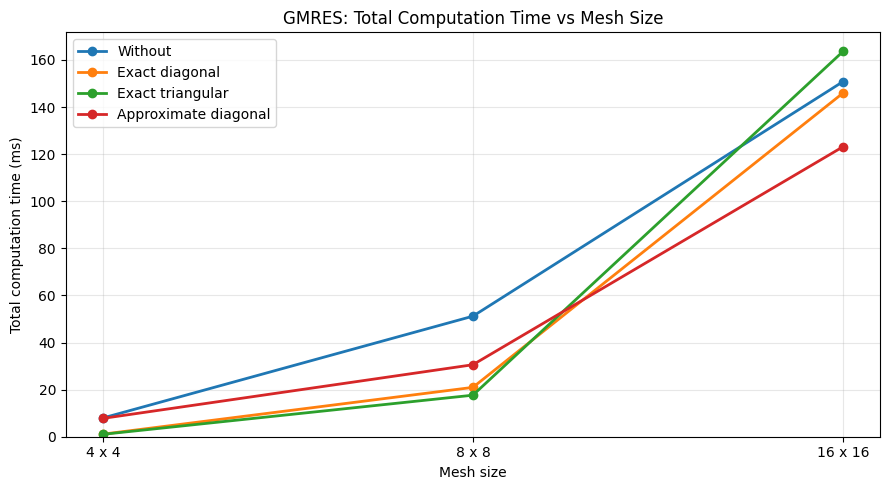

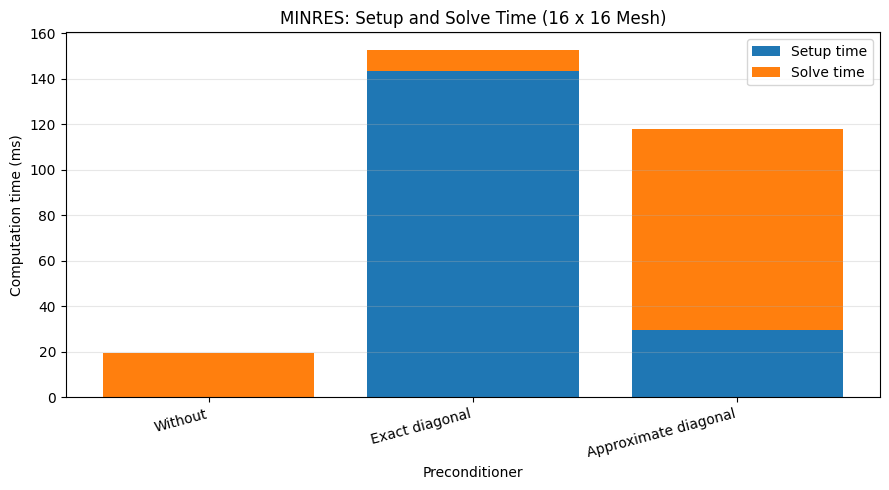

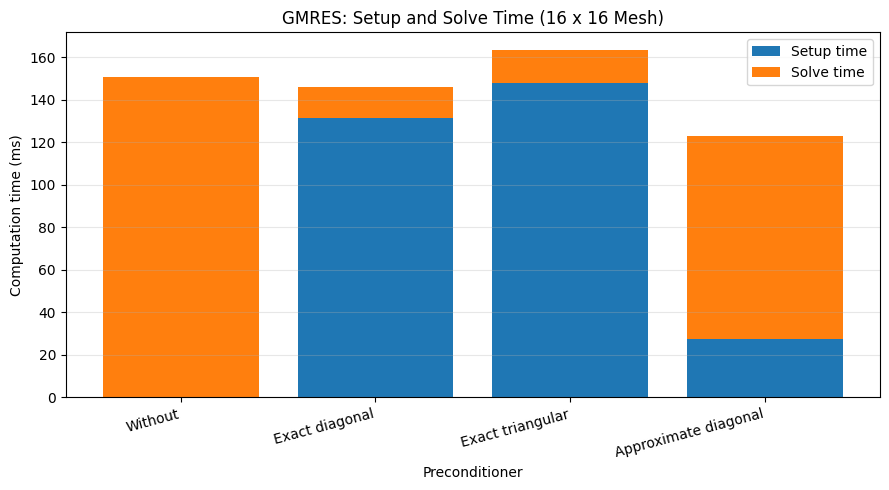

In [25]:
# Step 15: Plot computation times

import matplotlib.pyplot as plt

# Plot total computation time for both solvers
for solver in ["MINRES", "GMRES"]:

    solver_data = time_results_df[
        time_results_df["Solver"] == solver
    ]

    plt.figure(figsize=(9, 5))

    for kind in solver_data["Preconditioner"].unique():

        data = solver_data[
            solver_data["Preconditioner"] == kind
        ]

        plt.plot(
            data["Mesh"],
            data["Total time (ms)"],
            marker="o",
            linewidth=2,
            label=kind
        )

    plt.xlabel("Mesh size")
    plt.ylabel("Total computation time (ms)")
    plt.title(f"{solver}: Total Computation Time vs Mesh Size")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.ylim(bottom=0)
    plt.tight_layout()
    plt.show()


# Select the largest mesh
largest_mesh_data = time_results_df[
    time_results_df["Mesh"] == "16 x 16"
]

# Plot setup time and solve time
for solver in ["MINRES", "GMRES"]:

    data = largest_mesh_data[
        largest_mesh_data["Solver"] == solver
    ]

    plt.figure(figsize=(9, 5))

    # Plot setup time
    plt.bar(
        data["Preconditioner"],
        data["Setup time (ms)"],
        label="Setup time"
    )

    # Plot solve time above setup time
    plt.bar(
        data["Preconditioner"],
        data["Solve time (ms)"],
        bottom=data["Setup time (ms)"],
        label="Solve time"
    )

    plt.xlabel("Preconditioner")
    plt.ylabel("Computation time (ms)")
    plt.title(f"{solver}: Setup and Solve Time (16 x 16 Mesh)")
    plt.xticks(rotation=15, ha="right")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### Result

I plotted four graphs to compare the computational costs of different preconditioners.

The MINRES graph shows that the total computation time without a preconditioner was lower for all three tested mesh sizes.

For GMRES, the exact triangular preconditioner gave the lowest total computation time for the first two meshes. The approximate diagonal preconditioner gave the lowest total computation time for the largest mesh.

The stacked bar charts show the difference between the setup time and solve time.

I observed that the exact preconditioners had a high setup cost for the largest mesh.

The approximate preconditioner had a lower setup cost but required more solver iterations than the exact preconditioners.

These graphs helped me understand that fewer iterations do not always mean lower total computation time.

These observations are based on my current implementation, and the computation times may change when I run the notebook again.

## 16. Final Summary and Limitations

### Final Summary

In this notebook, I studied and implemented Schur complement preconditioners for a mixed Darcy saddle-point system.

I continued my work from the previous two notebooks and implemented three preconditioners:

- Exact block diagonal preconditioner.
- Exact block triangular preconditioner.
- Approximate block diagonal preconditioner.

I tested these preconditioners using MINRES and GMRES on three different mesh sizes.

### Main Findings

- The exact block diagonal preconditioner reduced the iteration counts for both MINRES and GMRES.
- The exact block triangular preconditioner also improved GMRES convergence.
- Both exact preconditioners maintained an iteration count of 2 wherever they were tested.
- The approximate preconditioner reduced the number of iterations, especially for larger systems.
- MINRES required stricter tolerances in some cases to reach the actual relative residual target.
- All 21 configurations in the mesh refinement study reached the actual relative residual target of 10⁻⁸.
- A smaller number of iterations did not always lead to a smaller total computation time.
- The setup cost was an important part of the total computational cost.

### Limitations

- I studied only a two-dimensional Darcy flow problem.
- I used a constant permeability and RT0–P0 finite elements.
- I tested only three mesh sizes, with a maximum of 1312 degrees of freedom.
- I used dense Cholesky factorization to apply the preconditioners, which can be expensive for larger systems.
- I excluded matrix assembly time from the computation time comparison.
- I repeated each timing test five times and calculated the average, but I did not study timing variability.
- The computation times depend on the implementation and computational environment.

### What I Learned

Through this notebook, I improved my understanding of Schur complements, block preconditioners, iterative solvers, and their computational costs.

I also learned that it is important to check the actual relative residual instead of relying only on the solver status.

This study helped me understand the trade-off between reducing iteration counts and reducing total computation time.

### Future Work

In the next notebook, I will study and implement a preconditioning approach based on artificial compressibility for the mixed Darcy saddle-point system.